# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Adrian Firdaus
- NIM   : 241011400332
- Kelas : Reg C

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library yang diizinkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 32  # dua digit terakhir NIM: 32
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
def train_test_split(X, y, test_size=0.2, random_state=32):
    """Split acak buatan sendiri dengan NumPy."""
    X = np.asarray(X); y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    idx = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float).reshape(-1, 1)
        Xb = np.c_[np.ones(len(X)), X]
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_ = float(theta[0, 0]); self.coef_ = theta[1:, 0]
        return self
    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate=learning_rate; self.n_iterations=n_iterations
    def fit(self, X, y):
        X=np.asarray(X,dtype=float); y=np.asarray(y,dtype=float).reshape(-1,1)
        Xb=np.c_[np.ones(len(X)),X]; theta=np.zeros((Xb.shape[1],1)); self.loss_history=[]
        for _ in range(self.n_iterations):
            err=Xb@theta-y
            with np.errstate(over='ignore', invalid='ignore'):
                loss=float(np.mean(err**2))
                grad=(2/len(y))*Xb.T@err
                theta=theta-self.learning_rate*grad
            self.loss_history.append(loss)
            if not np.all(np.isfinite(theta)):
                self.loss_history[-1]=np.inf
                break
        self.intercept_=float(theta[0,0]) if np.isfinite(theta[0,0]) else np.nan
        self.coef_=theta[1:,0] if np.all(np.isfinite(theta[1:,0])) else np.full(X.shape[1],np.nan)
        return self
    def predict(self,X): return self.intercept_+np.asarray(X,dtype=float)@self.coef_

def mae(y, pred): return float(np.mean(np.abs(np.asarray(y).ravel()-np.asarray(pred).ravel())))
def mse(y, pred): return float(np.mean((np.asarray(y).ravel()-np.asarray(pred).ravel())**2))
def rmse(y, pred): return float(np.sqrt(mse(y,pred)))
def r2_score(y,pred):
    y=np.asarray(y).ravel(); pred=np.asarray(pred).ravel()
    return float(1-np.sum((y-pred)**2)/np.sum((y-y.mean())**2))

def sigmoid(z):
    z=np.clip(z,-500,500)
    return 1/(1+np.exp(-z))
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate=learning_rate; self.n_iterations=n_iterations
    def fit(self,X,y):
        X=np.asarray(X,dtype=float); y=np.asarray(y,dtype=float).reshape(-1,1)
        Xb=np.c_[np.ones(len(X)),X]; theta=np.zeros((Xb.shape[1],1)); self.loss_history=[]
        for _ in range(self.n_iterations):
            p=sigmoid(Xb@theta)
            loss=-np.mean(y*np.log(p+1e-12)+(1-y)*np.log(1-p+1e-12))
            grad=Xb.T@(p-y)/len(y)
            theta-=self.learning_rate*grad
            self.loss_history.append(float(loss))
        self.intercept_=float(theta[0,0]); self.coef_=theta[1:,0]
        return self
    def predict_proba(self,X):
        X=np.asarray(X,dtype=float); return sigmoid(self.intercept_+X@self.coef_).ravel()
    def predict(self,X,threshold=0.5): return (self.predict_proba(X)>=threshold).astype(int)

def confusion_matrix(y_true,y_pred):
    y_true=np.asarray(y_true).astype(int).ravel(); y_pred=np.asarray(y_pred).astype(int).ravel()
    return np.array([[np.sum((y_true==0)&(y_pred==0)),np.sum((y_true==0)&(y_pred==1))],
                     [np.sum((y_true==1)&(y_pred==0)),np.sum((y_true==1)&(y_pred==1))]])
def accuracy_score(y_true,y_pred): return float(np.mean(np.asarray(y_true).ravel()==np.asarray(y_pred).ravel()))
def classification_metrics(y_true,y_pred):
    tn,fp,fn,tp=confusion_matrix(y_true,y_pred).ravel()
    precision=tp/(tp+fp) if tp+fp else 0.0
    recall=tp/(tp+fn) if tp+fn else 0.0
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {'Accuracy':accuracy_score(y_true,y_pred),'Precision':precision,'Recall':recall,'F1':f1,'TN':tn,'FP':fp,'FN':fn,'TP':tp}


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


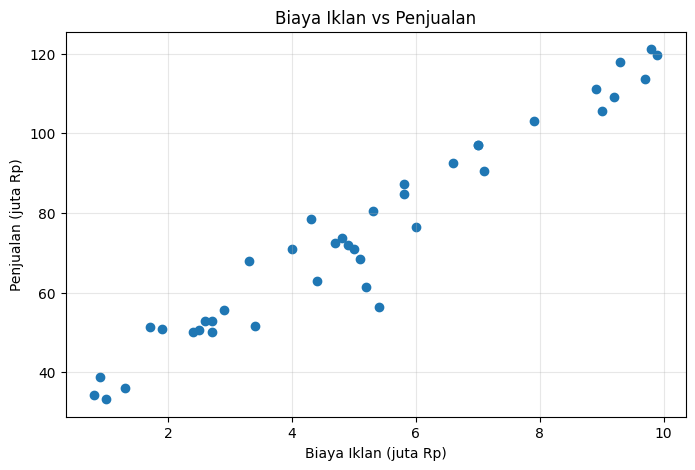

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
display(df_ads.head())
print("Jumlah baris:", len(df_ads))
X_ads = df_ads[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = df_ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)
plt.scatter(X_ads[:,0], y_ads)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)"); plt.grid(alpha=.3); plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

X_train: (32, 1) X_test: (8, 1)
y_train: (32,) y_test: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
model_lr = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {model_lr.intercept_:.4f}")
print(f"Koefisien (m): {model_lr.coef_[0]:.4f}")
print(f"Persamaan: ŷ = {model_lr.intercept_:.4f} + ({model_lr.coef_[0]:.4f})X")

Intercept (b): 27.4270
Koefisien (m): 9.2878
Persamaan: ŷ = 27.4270 + (9.2878)X


**Jawaban A3 (interpretasi):**

Koefisien menunjukkan perubahan penjualan yang diperkirakan ketika biaya iklan naik 1 juta rupiah. Berdasarkan koefisien hasil model di atas, setiap tambahan Rp1 juta biaya iklan diperkirakan mengubah penjualan sebesar nilai koefisien tersebut juta rupiah. Ini menunjukkan hubungan pada data, bukan jaminan sebab-akibat.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def regression_row(split, y, pred):
    return {"Data":split,"MAE":mae(y,pred),"MSE":mse(y,pred),"RMSE":rmse(y,pred),"R²":r2_score(y,pred)}
metrics_reg = pd.DataFrame([regression_row("Training",y_train,model_lr.predict(X_train)), regression_row("Testing",y_test,model_lr.predict(X_test))])
display(metrics_reg.round(4))

,Data,MAE,MSE,RMSE,R²
0,Training,3.9704,34.2313,5.8508,0.9517
1,Testing,6.3619,44.3620,6.6605,0.8260


**Jawaban A4 (analisis):**

MAE dan RMSE menunjukkan rata-rata besar kesalahan prediksi dalam satuan juta rupiah; semakin kecil nilainya semakin baik. R² mengukur seberapa baik model menjelaskan variasi penjualan, dan nilai yang lebih dekat ke 1 umumnya lebih baik. Bandingkan baris training dan testing pada tabel: jika hasil testing jauh lebih buruk, model mungkin kurang mampu menggeneralisasi data baru.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

c:\Users\Adrian\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\internals\blocks.py:1986: RuntimeWarning: overflow encountered in multiply
  values = self.values.round(decimals)  # type: ignore[union-attr]


,Learning rate,Intercept,Koefisien,Loss akhir
0,0.001,25.24967,9.62831,35.42437
1,0.020,27.42696,9.28781,34.23128
2,0.100,-inf,NaN,inf


c:\Users\Adrian\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


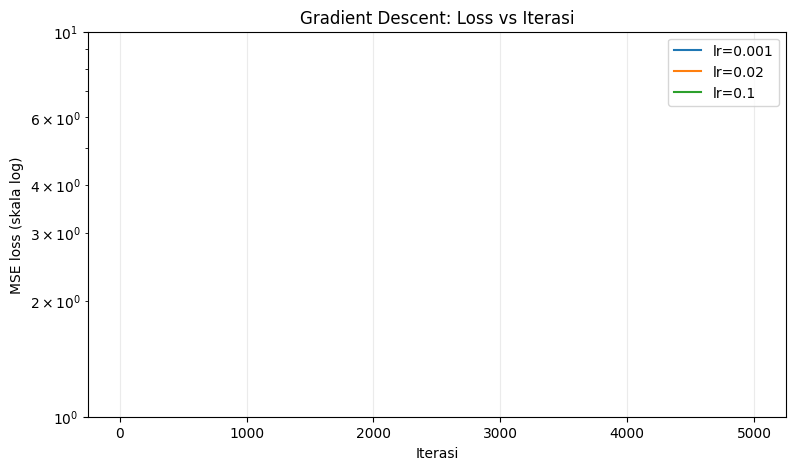

Normal equation: b=27.4270, m=9.2878


In [7]:
# Jawaban A5
learning_rates=[0.001,0.02,0.1]
gd_models={}
rows=[]
for lr in learning_rates:
    gd=LinearRegressionGD(learning_rate=lr,n_iterations=5000).fit(X_train,y_train)
    gd_models[lr]=gd
    rows.append({"Learning rate":lr,"Intercept":gd.intercept_,"Koefisien":gd.coef_[0],"Loss akhir":gd.loss_history[-1]})
display(pd.DataFrame(rows).round(5))
plt.figure(figsize=(9,5))
for lr,gd in gd_models.items():
    loss=np.asarray(gd.loss_history)
    plt.plot(np.arange(1,len(loss)+1), np.maximum(loss,1e-12), label=f"lr={lr}")
plt.yscale("log"); plt.xlabel("Iterasi"); plt.ylabel("MSE loss (skala log)")
plt.title("Gradient Descent: Loss vs Iterasi"); plt.legend(); plt.grid(alpha=.25); plt.show()
print("Normal equation: b=%.4f, m=%.4f"%(model_lr.intercept_,model_lr.coef_[0]))

**Jawaban A5 (analisis):**

Lihat grafik loss dan tabel koefisien di atas. Learning rate 0.001 biasanya bergerak lebih lambat karena langkah pembaruan kecil, sedangkan 0.02 menggunakan langkah lebih besar. Learning rate 0.1 dapat gagal konvergen pada fitur yang belum dinormalisasi karena pembaruan parameter terlalu besar sehingga loss melonjak atau menjadi tak hingga. Bandingkan nilai akhir dengan normal equation; hasil yang dekat dengan intercept dan koefisien normal equation menandakan proses sudah mendekati solusi.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

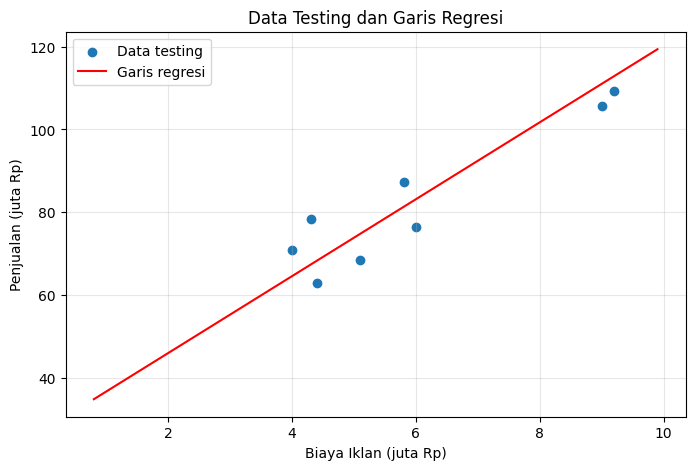

,Biaya Iklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,69.222
1,7.0,92.442
2,12.0,138.881


In [8]:
# Jawaban A6
plt.scatter(X_test[:,0],y_test,label="Data testing")
x_line=np.linspace(X_ads[:,0].min(),X_ads[:,0].max(),100).reshape(-1,1)
plt.plot(x_line[:,0],model_lr.predict(x_line),color="red",label="Garis regresi")
plt.title("Data Testing dan Garis Regresi"); plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)"); plt.legend(); plt.grid(alpha=.3); plt.show()
biaya_baru=np.array([[4.5],[7.0],[12.0]])
pred_baru=model_lr.predict(biaya_baru)
display(pd.DataFrame({"Biaya Iklan (juta Rp)":biaya_baru.ravel(),"Prediksi Penjualan (juta Rp)":pred_baru}).round(3))

**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4,5 dan 7 juta berada lebih dekat dengan rentang data yang diamati sehingga relatif lebih masuk akal. Biaya iklan 12 juta berada di luar rentang dataset, sehingga merupakan ekstrapolasi. Hubungan garis yang dipelajari dari data yang ada belum tentu tetap berlaku di luar rentang tersebut, jadi prediksi 12 juta perlu dianggap lebih tidak pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas (0=Bukan Spam, 1=Spam):


,Jumlah email
Spam,
Bukan Spam,35
Spam,25


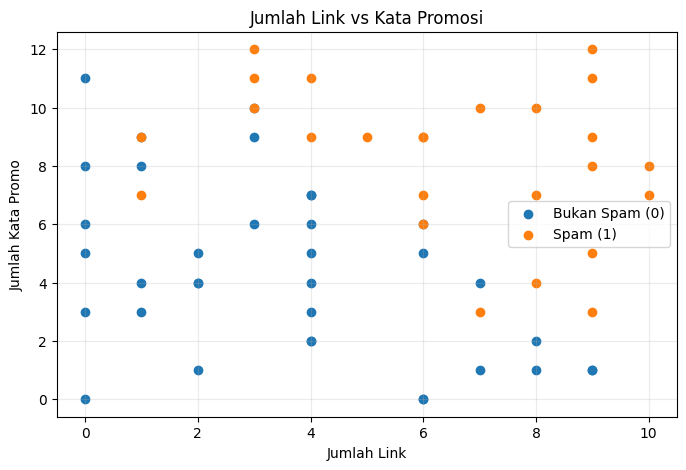

In [9]:
# Jawaban B1
df_email=pd.read_csv("Email_Data.csv")
display(df_email.head())
print("Jumlah kelas (0=Bukan Spam, 1=Spam):")
display(df_email["Spam"].value_counts().sort_index().rename(index={0:"Bukan Spam",1:"Spam"}).to_frame("Jumlah email"))
X_email=df_email[["JumlahLink","KataPromo"]].to_numpy(dtype=float)
y_email=df_email["Spam"].to_numpy(dtype=int)
plt.scatter(df_email.loc[df_email.Spam==0,"JumlahLink"],df_email.loc[df_email.Spam==0,"KataPromo"],label="Bukan Spam (0)")
plt.scatter(df_email.loc[df_email.Spam==1,"JumlahLink"],df_email.loc[df_email.Spam==1,"KataPromo"],label="Spam (1)")
plt.title("Jumlah Link vs Kata Promosi"); plt.xlabel("Jumlah Link"); plt.ylabel("Jumlah Kata Promo"); plt.legend(); plt.grid(alpha=.25); plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape: (45, 2) (15, 2) (45,) (15,)
Intercept (b): -11.18057
Koefisien (m1, m2): [1.0002 0.9637]
P(Spam)=sigmoid(-11.18057 + (1.00021)*JumlahLink + (0.96368)*KataPromo)


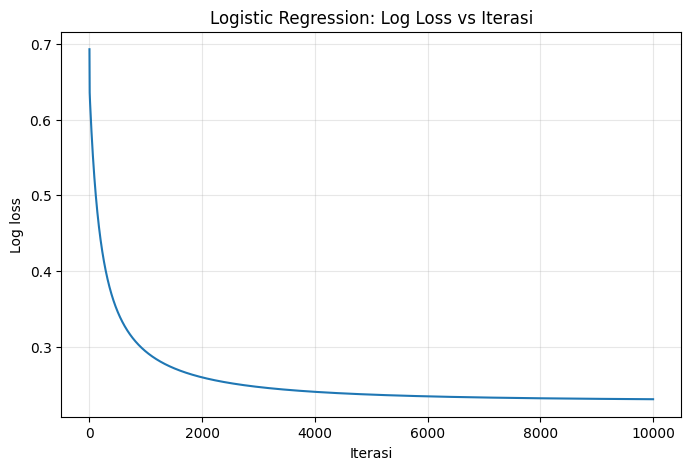

Log loss awal: 0.69315 | akhir: 0.23041


In [10]:
# Jawaban B2
Xtr, Xte, ytr, yte = train_test_split(X_email,y_email,test_size=0.25,random_state=RANDOM_STATE)
print("Shape:",Xtr.shape,Xte.shape,ytr.shape,yte.shape)
model_log=LogisticRegression(learning_rate=0.1,n_iterations=10000).fit(Xtr,ytr)
print(f"Intercept (b): {model_log.intercept_:.5f}")
print("Koefisien (m1, m2):",model_log.coef_)
print(f"P(Spam)=sigmoid({model_log.intercept_:.5f} + ({model_log.coef_[0]:.5f})*JumlahLink + ({model_log.coef_[1]:.5f})*KataPromo)")
plt.plot(model_log.loss_history); plt.xlabel("Iterasi"); plt.ylabel("Log loss"); plt.title("Logistic Regression: Log Loss vs Iterasi"); plt.grid(alpha=.3); plt.show()
print("Log loss awal: %.5f | akhir: %.5f"%(model_log.loss_history[0],model_log.loss_history[-1]))

**Jawaban B2 (analisis):**

Perhatikan grafik log loss: penurunan loss menunjukkan model semakin baik menyesuaikan prediksi probabilitas dengan label sebenarnya. Jika kurva mulai mendatar di bagian akhir, proses optimasi mulai stabil. Intercept dan kedua koefisien membentuk skor linear yang kemudian diubah sigmoid menjadi probabilitas antara 0 dan 1.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
y_pred=model_log.predict(Xte,threshold=0.5)
cm=confusion_matrix(yte,y_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
metrics_cls=classification_metrics(yte,y_pred)
display(pd.DataFrame([metrics_cls]).round(4))

Confusion matrix [[TN, FP], [FN, TP]]:
[[12  1]
 [ 1  1]]


,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
0,0.8667,0.5,0.5,0.5,12,1,1,1


**Jawaban B3 (analisis):**

FP berarti email sebenarnya bukan spam tetapi ditandai sebagai spam, sehingga pesan penting bisa masuk folder spam. FN berarti email spam justru dianggap bukan spam, sehingga pesan promosi yang tidak diinginkan masuk kotak masuk. Menurut saya FP dapat lebih merugikan jika email penting terlewat, tetapi FN juga mengganggu karena spam lolos; pilihan bergantung pada kebutuhan pengguna.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-11.18057 + (1.00021)*JumlahLink)/(0.96368)


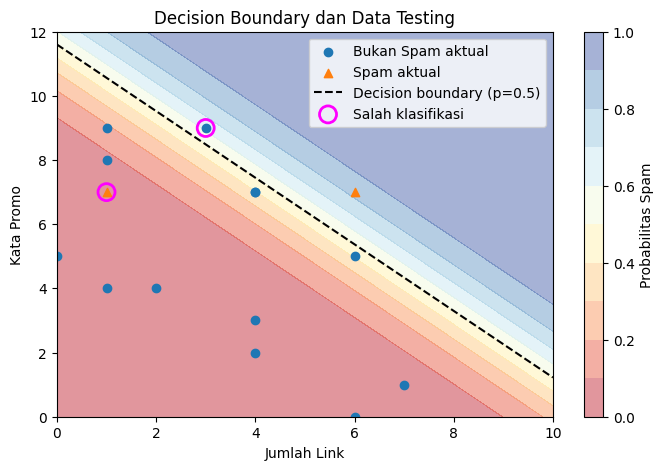

Data testing salah klasifikasi:


,JumlahLink,KataPromo,Aktual,Prediksi
0,1.0,7.0,1,0
1,3.0,9.0,0,1


In [12]:
# Jawaban B4
m1,m2=model_log.coef_
if abs(m2)>1e-12:
    print(f"Decision boundary: KataPromo = -({model_log.intercept_:.5f} + ({m1:.5f})*JumlahLink)/({m2:.5f})")
    x1=np.linspace(0,10,150); x2=np.linspace(0,12,150)
    xx1,xx2=np.meshgrid(x1,x2)
    probs=sigmoid(model_log.intercept_+m1*xx1+m2*xx2)
    plt.contourf(xx1,xx2,probs,levels=np.linspace(0,1,11),alpha=.45,cmap="RdYlBu")
    plt.colorbar(label="Probabilitas Spam")
    plt.scatter(Xte[yte==0,0],Xte[yte==0,1],marker="o",label="Bukan Spam aktual")
    plt.scatter(Xte[yte==1,0],Xte[yte==1,1],marker="^",label="Spam aktual")
    xx=np.linspace(0,10,100); yy=-(model_log.intercept_+m1*xx)/m2
    plt.plot(xx,yy,'k--',label="Decision boundary (p=0.5)")
    wrong=y_pred!=yte
    plt.scatter(Xte[wrong,0],Xte[wrong,1],s=150,facecolors="none",edgecolors="magenta",linewidths=2,label="Salah klasifikasi")
    plt.xlim(0,10); plt.ylim(0,12); plt.xlabel("Jumlah Link"); plt.ylabel("Kata Promo"); plt.title("Decision Boundary dan Data Testing"); plt.legend(); plt.show()
    wrong_df=pd.DataFrame(Xte[wrong],columns=["JumlahLink","KataPromo"]); wrong_df["Aktual"]=yte[wrong]; wrong_df["Prediksi"]=y_pred[wrong]
    print("Data testing salah klasifikasi:"); display(wrong_df if len(wrong_df) else pd.DataFrame(columns=["JumlahLink","KataPromo","Aktual","Prediksi"]))
else: print("Koefisien KataPromo mendekati nol; garis boundary tidak dapat ditampilkan sebagai x2=f(x1).")

**Jawaban B4 (analisis):**

Garis decision boundary menunjukkan kombinasi fitur saat probabilitas spam sama dengan 0,5. Area dengan probabilitas lebih besar dari atau sama dengan 0,5 diprediksi sebagai spam pada threshold default. Titik yang dilingkari magenta pada grafik adalah data testing yang prediksinya tidak sama dengan label aktual; tabel di bawah grafik menampilkan nilainya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
rows=[]
for th in [0.3,0.5,0.7]:
    yp=(model_log.predict_proba(Xte)>=th).astype(int)
    cm_th=confusion_matrix(yte,yp); met=classification_metrics(yte,yp)
    rows.append({"Threshold":th,"TN":cm_th[0,0],"FP":cm_th[0,1],"FN":cm_th[1,0],"TP":cm_th[1,1],"Precision":met["Precision"],"Recall":met["Recall"]})
threshold_table=pd.DataFrame(rows)
display(threshold_table.round(4))
# Pilihan default: 0.5 sebagai kompromi awal; hasil ketiga threshold dapat ditinjau di atas
THRESHOLD_PILIHAN=0.5
print("Threshold pilihan untuk soal B6:",THRESHOLD_PILIHAN)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,9,4,1,1,0.2,0.5
1,0.5,12,1,1,1,0.5,0.5
2,0.7,13,0,1,1,1.0,0.5


Threshold pilihan untuk soal B6: 0.5


**Jawaban B5 (analisis):**

Threshold lebih rendah (0,3) cenderung menandai lebih banyak email sebagai spam, sehingga recall biasanya naik tetapi false positive juga dapat bertambah dan precision bisa turun. Threshold lebih tinggi (0,7) lebih ketat, sehingga prediksi spam lebih sedikit; precision dapat meningkat tetapi recall dapat menurun. Saya memilih threshold 0,5 sebagai titik awal yang seimbang, lalu pilihan akhir sebaiknya disesuaikan dengan tabel: jika lebih penting menangkap sebanyak mungkin spam, pertimbangkan threshold lebih rendah; jika email penting sering salah masuk spam, gunakan threshold lebih tinggi.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
email_baru=pd.DataFrame({"Email":["E1","E2","E3","E4"],"JumlahLink":[1,5,9,2],"KataPromo":[2,6,10,11]})
proba=model_log.predict_proba(email_baru[["JumlahLink","KataPromo"]].to_numpy())
email_baru["Probabilitas Spam"]=proba
email_baru["Prediksi Kelas"]=(proba>=THRESHOLD_PILIHAN).astype(int)
email_baru["Keterangan"]=email_baru["Prediksi Kelas"].map({0:"Bukan Spam",1:"Spam"})
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Kelas,Keterangan
0,E1,1,2,0.0003,0,Bukan Spam
1,E2,5,6,0.4019,0,Bukan Spam
2,E3,9,10,0.9994,1,Spam
3,E4,2,11,0.8054,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut regresi karena menghitung kombinasi linear dari fitur, tetapi hasil akhirnya dipakai untuk menentukan kelas. Fungsi sigmoid mengubah skor tersebut menjadi probabilitas antara 0 dan 1. Probabilitas itu kemudian dibandingkan dengan threshold untuk menentukan kelas, misalnya spam atau bukan spam.

**Jawaban C2:** Normal equation menghitung parameter secara langsung menggunakan operasi matriks sehingga tidak memerlukan iterasi. Gradient descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient descent lebih berguna saat data atau jumlah fitur besar sehingga perhitungan matriks langsung menjadi mahal, tetapi learning rate harus dipilih dengan tepat.

**Jawaban C3:** Data training digunakan untuk mempelajari parameter model, sehingga hasilnya cenderung lebih baik pada data tersebut. Data testing dipakai untuk memperkirakan kemampuan model pada data baru yang belum pernah dilihat. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training dan performanya menurun pada data baru.

**Jawaban C4:** Linear Regression memprediksi nilai numerik, sehingga MSE mengukur kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa tepat probabilitas yang diberikan terhadap label sebenarnya. Log loss memberi hukuman besar ketika model sangat yakin tetapi prediksinya salah.

**Jawaban C5:** Hasil bisa berbeda karena pembagian data training dan testing dapat berbeda jika random state berbeda. Perbedaan inisialisasi parameter, learning rate, jumlah iterasi, threshold, dan cara optimasi juga memengaruhi hasil. Karena itu, penggunaan random state dan pengaturan eksperimen yang sama membantu membuat perbandingan lebih adil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus (scikit-learn hanya untuk perbandingan)
try:
    from sklearn.linear_model import LinearRegression as SKLinearRegression
    from sklearn.linear_model import LogisticRegression as SKLogisticRegression
    sk_lr=SKLinearRegression().fit(X_train,y_train)
    sk_pred_reg=sk_lr.predict(X_test)
    print("Linear Regression - implementasi sendiri vs sklearn")
    print("Intercept:",model_lr.intercept_,"vs",sk_lr.intercept_)
    print("Koefisien:",model_lr.coef_,"vs",sk_lr.coef_)
    print("R2 testing:",r2_score(y_test,model_lr.predict(X_test)),"vs",r2_score(y_test,sk_pred_reg))
    sk_log=SKLogisticRegression(max_iter=10000,random_state=RANDOM_STATE).fit(Xtr,ytr)
    sk_pred=sk_log.predict(Xte)
    print("\nLogistic Regression - implementasi sendiri vs sklearn")
    print("Intercept:",model_log.intercept_,"vs",sk_log.intercept_[0])
    print("Koefisien:",model_log.coef_,"vs",sk_log.coef_[0])
    print("Accuracy testing:",accuracy_score(yte,model_log.predict(Xte)),"vs",accuracy_score(yte,sk_pred))
except ImportError:
    print("scikit-learn tidak tersedia; bagian bonus dilewati. Soal utama tetap menggunakan NumPy.")

Linear Regression - implementasi sendiri vs sklearn
Intercept: 27.426961994323744 vs 27.426961994323648
Koefisien: [9.2878] vs [9.2878]
R2 testing: 0.8260141875998538 vs 0.8260141875998526

Logistic Regression - implementasi sendiri vs sklearn
Intercept: -11.180570208513666 vs -10.398104409570205
Koefisien: [1.0002 0.9637] vs [0.9224 0.8992]
Accuracy testing: 0.8666666666666667 vs 0.8666666666666667


**Jawaban Bonus (analisis):**

Linear Regression dari normal equation seharusnya menghasilkan koefisien yang sangat dekat dengan scikit-learn karena keduanya mencari solusi kuadrat terkecil. Logistic Regression dapat berbeda karena scikit-learn secara default menggunakan regularisasi L2 dan optimisasi solver tertentu, sedangkan implementasi sendiri di notebook ini menggunakan gradient descent tanpa regularisasi. Perbedaan regularisasi, toleransi berhenti, dan proses optimasi dapat menghasilkan koefisien serta prediksi yang berbeda.